# Part A: Pool analysis (Dev Salvi)

Streaming-Order AMM, FRE-GY 6931. This notebook covers the pool side: price impact, impermanent loss (IL), and LP profit and loss including fees. Part B (slicing versus lump sum, Aditya) lives in its own notebook.

**Questions answered**
1. How does price impact grow with trade size as a percentage of reserves, and how does it change with fee and pool depth?
2. How large is impermanent loss across a range of price moves, and does simulation agree with the closed form `2*sqrt(r)/(1+r) - 1`?
3. Over a simulated price path, do the fees an LP earns cover the IL, and how does that change with fee, depth and volatility?

**Assumptions (stated once, referenced below)**

| # | Assumption | Why it matters |
|---|---|---|
| A1 | Pool is constant product `x*y = k` with a 30 bps fee taken from the input amount and left in the reserves (same as `Pool.sol`) | Fees raise `k`, which is how LPs earn |
| A2 | Starting pool is 500 WBTC and 30,000,000 USDC, so the price is 60,000 USDC per BTC and TVL is 60M USDC | Matches the 500 BTC example in the proposal |
| A3 | `swap_out_int` below uses floor division on integers exactly as the contract will, so contract tests can reuse these numbers | Reproducibility |
| A4 | The external ("true") price follows a driftless geometric Brownian motion (log-drift `-sigma^2/2`, so the price is a martingale), 60% annual volatility, hourly steps, 30 days | Crypto-like volatility, no directional bet |
| A5 | One arbitrageur trades the pool to the exact no-profit boundary each hour, with no gas cost, no latency and no competition | Best case for price tracking; gas would make real arbitrage rarer |
| A6 | Organic (non-arbitrage) volume is a fixed USD amount per day (default 6M, 10% of starting TVL), balanced between buys and sells so it earns the fee but does not move the price | Isolates the fee effect |
| A7 | The LP is compared with simply holding the deposited tokens (HODL), valued at the external price | This is what IL measures |
| A8 | No protocol fee split, no LP-token incentives, no taxes. Fees are reinvested in the pool | The proposal's protocol fee split is a revenue question for the report, not for LP maths |
| A9 | Returns are relative, so the size of the LP's share of the pool does not matter | Simplifies |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fractions import Fraction

# Validated categorical colours (blue, orange) plus neutral ink. Series are also told apart by line style.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e3e2de"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "axes.titleweight": "bold", "axes.titlesize": 11,
})

BPS = 10_000
WBTC, USDC = 10**8, 10**6            # raw units per token (8 and 6 decimals)
X0_BTC, P0 = 500, 60_000.0           # A2
FEE_BPS = 30                         # A1

## 0. The pool model, in integer maths

`swap_out_int` is the exact formula `Pool.swapExactIn` will use (A3). The fee is deducted from the input before the curve is applied, and the whole input (fee included) is added to the reserve:

```
amountInWithFee = amountIn * (10000 - feeBps)
amountOut       = amountInWithFee * reserveOut // (reserveIn * 10000 + amountInWithFee)
```

In [2]:
def swap_out_int(amount_in, r_in, r_out, fee_bps=FEE_BPS):
    a = amount_in * (BPS - fee_bps)
    return a * r_out // (r_in * BPS + a)

def spot_e18(r0, r1):
    """Contract price (IPool.spotPriceE18): USDC per ONE WHOLE WBTC, scaled by 1e18. 60,000 USDC/BTC = 60_000e18."""
    return r1 * 10**8 * 10**18 // (r0 * 10**6)

x_raw, y_raw = X0_BTC * WBTC, 30_000_000 * USDC

# Hand-computed vector: sell exactly 1 WBTC into the 500 WBTC / 30M USDC pool.
amount_in = 1 * WBTC
num = amount_in * 9970 * y_raw
den = x_raw * 10_000 + amount_in * 9970
exact = Fraction(num, den)                      # exact rational answer
out = swap_out_int(amount_in, x_raw, y_raw)
print("amountOut (raw USDC units):", out, " exact rational:", float(exact))
print("amountOut in USDC:", out / USDC, "  execution price:", out / USDC, "USDC/BTC")
assert out == num // den == int(exact)           # floor division, as in Solidity
print("spotPriceE18 before trade:", spot_e18(x_raw, y_raw))
assert spot_e18(x_raw, y_raw) == 60_000 * 10**18

amountOut (raw USDC units): 59700956293  exact rational: 59700956293.15146
amountOut in USDC: 59700.956293   execution price: 59700.956293 USDC/BTC
spotPriceE18 before trade: 60000000000000000000000


## 1. Price impact versus trade size

**Definition.** Selling `f * x` of token0 into reserves `(x, y)` with `gamma = 1 - fee` gives execution price relative to the pre-trade spot of

`exec / spot = gamma / (1 + gamma * f)`, so `impact = 1 - gamma / (1 + gamma * f)`.

This depends only on the fraction `f` of the reserve being traded, not on the absolute reserve size. Depth matters because a given *dollar* trade is a different fraction `f` of a deeper pool (second chart).

In [3]:
def impact(f, fee_bps=FEE_BPS):
    g = 1 - fee_bps / BPS
    return 1 - g / (1 + g * f)

# Check the closed form against the integer pool for several trade sizes.
fs = np.array([0.0001, 0.001, 0.005, 0.01, 0.025, 0.05, 0.10, 0.20])
rows = []
for f in fs:
    amt = int(f * x_raw)
    o = swap_out_int(amt, x_raw, y_raw)
    imp_int = 1 - (o / amt) / (y_raw / x_raw)
    rows.append({"trade as % of reserve": f * 100, "trade (BTC)": amt / WBTC,
                 "impact, 30 bps (int pool) %": imp_int * 100, "impact, 30 bps (formula) %": impact(f) * 100,
                 "impact, no fee %": impact(f, 0) * 100})
    assert abs(imp_int - impact(f)) < 1e-6
df = pd.DataFrame(rows).round(4)
df

,trade as % of reserve,trade (BTC),"impact, 30 bps (int pool) %","impact, 30 bps (formula) %","impact, no fee %"
0,0.01,0.05,0.3099,0.3099,0.0100
1,0.10,0.50,0.3993,0.3993,0.0999
2,0.50,2.50,0.7945,0.7945,0.4975
3,1.00,5.00,1.2842,1.2842,0.9901
4,2.50,12.50,2.7246,2.7246,2.4390
5,5.00,25.00,5.0341,5.0341,4.7619
6,10.00,50.00,9.3389,9.3389,9.0909
7,20.00,100.00,16.8751,16.8751,16.6667


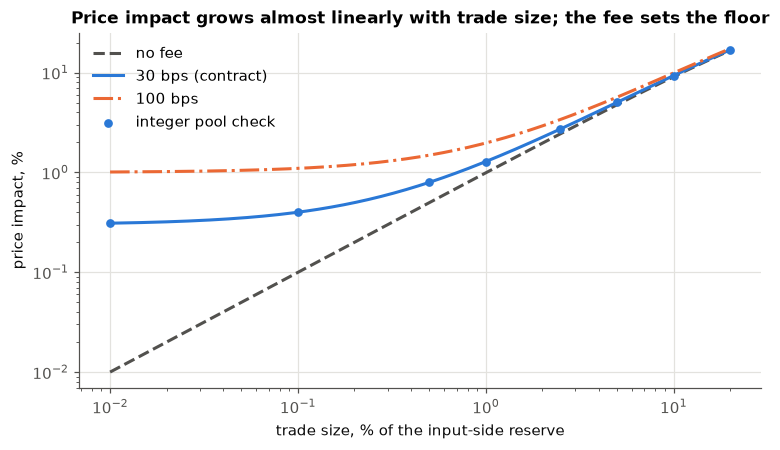

   50 BTC into 500 BTC: impact 9.09% without fee, 9.34% with 30 bps fee
  2.5 BTC into 500 BTC: impact 0.50% without fee, 0.79% with 30 bps fee


In [4]:
f_grid = np.logspace(-4, np.log10(0.20), 200)
fig, ax = plt.subplots()
ax.plot(f_grid * 100, impact(f_grid, 0) * 100, color=MUTED, ls="--", label="no fee")
ax.plot(f_grid * 100, impact(f_grid, 30) * 100, color=BLUE, label="30 bps (contract)")
ax.plot(f_grid * 100, impact(f_grid, 100) * 100, color=ORANGE, ls="-.", label="100 bps")
ax.scatter(fs * 100, [impact(f) * 100 for f in fs], color=BLUE, zorder=3, s=22, label="integer pool check")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("trade size, % of the input-side reserve"); ax.set_ylabel("price impact, %")
ax.set_title("Price impact grows almost linearly with trade size; the fee sets the floor")
ax.legend(); plt.show()

# Proposal example: 50 BTC into 500 BTC, versus a 2.5 BTC slice.
for btc in (50, 2.5):
    f = btc / 500
    print(f"{btc:>5} BTC into 500 BTC: impact {impact(f, 0)*100:.2f}% without fee, {impact(f)*100:.2f}% with 30 bps fee")

**Reading it.** At 0.01% of the reserve the impact is just the 0.30% fee. The curve part adds roughly `f` percent per percent of reserve traded: 50 BTC into 500 BTC (10%) costs about 9.1% before the fee and 9.3% with it, while a 2.5 BTC slice (0.5%) costs about 0.5% before the fee and 0.8% with it. That matches the proposal's "about 9%" and "about 0.5%" figures, with the fee added on top. A 100 bps fee shifts the whole curve up by about 0.7 percentage points; the shape does not change.

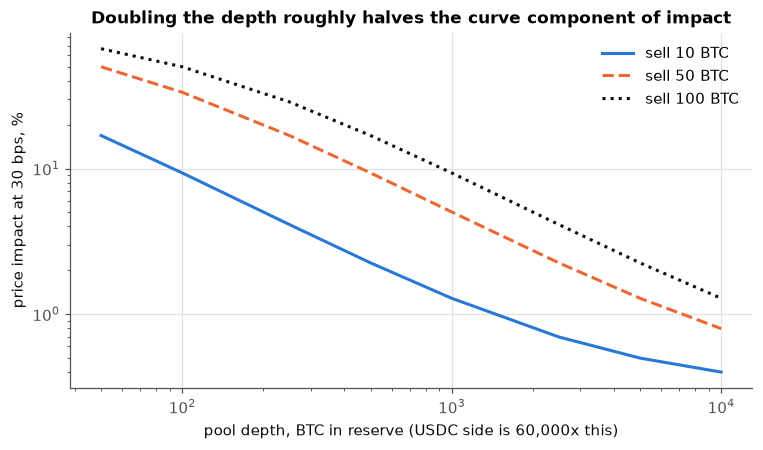

,sell 10 BTC,sell 50 BTC,sell 100 BTC
depth (BTC),,,
50,16.875,50.075,66.700
100,9.339,33.467,50.075
250,4.124,16.875,28.725
500,2.249,9.339,16.875
1000,1.284,5.034,9.339
2500,0.696,2.249,4.124
5000,0.498,1.284,2.249
10000,0.399,0.795,1.284


In [5]:
# Depth: the same absolute trade is a smaller fraction of a deeper pool (price held at 60,000).
depths = np.array([50, 100, 250, 500, 1000, 2500, 5000, 10000])
fig, ax = plt.subplots()
for btc, col, ls in [(10, BLUE, "-"), (50, ORANGE, "--"), (100, INK, ":")]:
    ax.plot(depths, impact(btc / depths) * 100, color=col, ls=ls, label=f"sell {btc} BTC")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("pool depth, BTC in reserve (USDC side is 60,000x this)"); ax.set_ylabel("price impact at 30 bps, %")
ax.set_title("Doubling the depth roughly halves the curve component of impact"); ax.legend(); plt.show()

tbl = pd.DataFrame({f"sell {b} BTC": [impact(b / d) * 100 for d in depths] for b in (10, 50, 100)}, index=depths)
tbl.index.name = "depth (BTC)"; tbl.round(3)

## 2. Impermanent loss across price moves

Let `r = P_T / P_0` be the external price at the end relative to the start. Without fees, an LP who deposited at `P_0` and whose pool is arbitrage-aligned to `P_T` holds `V_LP` against a HODL value `V_H`, and

`IL(r) = V_LP / V_H - 1 = 2*sqrt(r) / (1 + r) - 1`.

It is symmetric in `log r` (a doubling and a halving cost the same) and always zero or negative. Below, the closed form is checked three ways: float simulation with no fee, the integer pool with no fee, and the integer pool with the 30 bps fee (which opens a no-trade band around the starting price, so small moves cost nothing).

In [6]:
def il_closed(r):
    r = np.asarray(r, float)
    return 2 * np.sqrt(r) / (1 + r) - 1

def arb(x, y, P, g):
    """Move reserves (x BTC, y USDC) to the arbitrageur's no-profit point for external price P.
    g = 1 - fee. Fee stays in the pool (A1). Vectorised."""
    x, y, P = (np.asarray(v, float) for v in (x, y, P))
    up = P > y / (x * g)          # pool underprices BTC: arbitrageur pays USDC, takes BTC
    dn = P < g * y / x            # pool overprices BTC: arbitrageur pays BTC, takes USDC
    a = np.where(up, (np.sqrt(g * P * x * y) - y) / g, 0.0)
    b = np.where(dn, (np.sqrt(g * x * y / P) - x) / g, 0.0)
    x1 = np.where(up, x * y / (y + a * g), np.where(dn, x + b, x))
    y1 = np.where(up, y + a, np.where(dn, y * x / (x + b * g), y))
    return x1, y1

def il_sim(r, fee_bps):
    g = 1 - fee_bps / BPS
    x0, y0 = float(X0_BTC), X0_BTC * P0
    P = P0 * np.asarray(r, float)
    x1, y1 = arb(x0, y0, P, g)
    return (x1 * P + y1) / (x0 * P + y0) - 1

def il_int_pool(r, fee_bps):
    """Same move executed on the integer pool, one swap, floor division as in the contract."""
    g = 1 - fee_bps / BPS
    x, y = X0_BTC * WBTC, 30_000_000 * USDC
    P = P0 * r * USDC / WBTC                       # raw USDC per raw BTC
    if P > (y / x) / g:
        a = int((np.sqrt(g * P * x * y) - y) / g)  # USDC in
        out = swap_out_int(a, y, x, fee_bps); y, x = y + a, x - out
    elif P < g * (y / x):
        b = int((np.sqrt(g * x * y / P) - x) / g)  # BTC in
        out = swap_out_int(b, x, y, fee_bps); x, y = x + b, y - out
    Pn = P0 * r
    return ((x / WBTC) * Pn + y / USDC) / (X0_BTC * Pn + 30_000_000) - 1

rs = np.array([0.1, 0.25, 0.5, 0.8, 0.9, 1.0, 1.1, 1.25, 2.0, 4.0, 10.0])
tab = pd.DataFrame({
    "price move r": rs,
    "closed form %": il_closed(rs) * 100,
    "sim, no fee %": il_sim(rs, 0) * 100,
    "int pool, no fee %": [il_int_pool(r, 0) * 100 for r in rs],
    "sim, 30 bps %": il_sim(rs, 30) * 100,
    "int pool, 30 bps %": [il_int_pool(r, 30) * 100 for r in rs],
})
assert np.allclose(tab["closed form %"], tab["sim, no fee %"], atol=1e-9)
assert np.allclose(tab["closed form %"], tab["int pool, no fee %"], atol=1e-5)
assert np.allclose(tab["sim, 30 bps %"], tab["int pool, 30 bps %"], atol=1e-4)
tab.round(4)

,price move r,closed form %,"sim, no fee %","int pool, no fee %","sim, 30 bps %","int pool, 30 bps %"
0,0.10,-42.5040,-42.5040,-42.5040,-42.4450,-42.4450
1,0.25,-20.0000,-20.0000,-20.0000,-19.9399,-19.9399
2,0.50,-5.7191,-5.7191,-5.7191,-5.6777,-5.6777
3,0.80,-0.6192,-0.6192,-0.6192,-0.6035,-0.6035
4,0.90,-0.1386,-0.1386,-0.1386,-0.1310,-0.1310
5,1.00,0.0000,0.0000,0.0000,0.0000,0.0000
6,1.10,-0.1134,-0.1134,-0.1134,-0.1066,-0.1066
7,1.25,-0.6192,-0.6192,-0.6192,-0.6035,-0.6035
8,2.00,-5.7191,-5.7191,-5.7191,-5.6777,-5.6777
9,4.00,-20.0000,-20.0000,-20.0000,-19.9399,-19.9399


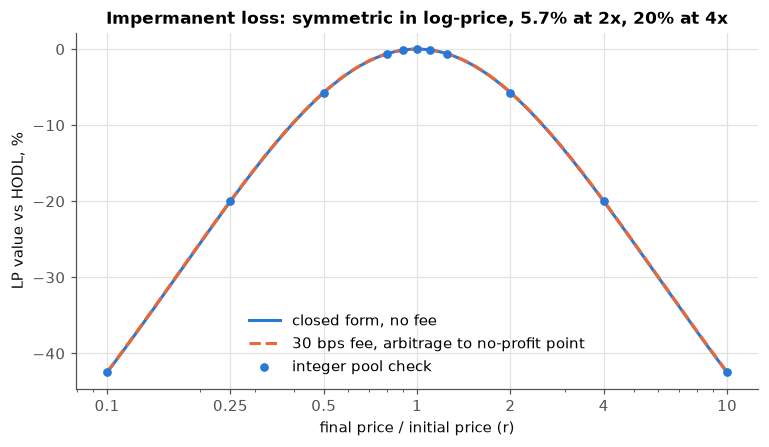

In [7]:
r_grid = np.exp(np.linspace(np.log(0.1), np.log(10), 400))
fig, ax = plt.subplots()
ax.plot(r_grid, il_closed(r_grid) * 100, color=BLUE, label="closed form, no fee")
ax.plot(r_grid, il_sim(r_grid, 30) * 100, color=ORANGE, ls="--", label="30 bps fee, arbitrage to no-profit point")
ax.scatter(rs, il_closed(rs) * 100, color=BLUE, s=22, zorder=3, label="integer pool check")
ax.set_xscale("log"); ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4, 10]); ax.set_xticklabels(["0.1", "0.25", "0.5", "1", "2", "4", "10"])
ax.set_xlabel("final price / initial price (r)"); ax.set_ylabel("LP value vs HODL, %")
ax.set_title("Impermanent loss: symmetric in log-price, 5.7% at 2x, 20% at 4x"); ax.legend(); plt.show()

**Reading it.** Closed form and both simulations agree to rounding (the asserts above enforce it): 2x or 0.5x costs 5.72%, 4x costs 20%, 10x costs 42%. The 30 bps fee only matters inside a band of about +/-0.3% around the starting price (zero IL there because nobody trades). Outside it, the fee the arbitrage trade leaves in the pool trims IL by just 0.04 to 0.06 percentage points (for example -5.72% becomes -5.68% at 2x). That is far too small to offset a big move, so LPs rely on fees earned over time, which is the next section.

## 3. LP profit and loss including fees, over a simulated price path

Each hour: the external price steps (A4), the arbitrageur realigns the pool (A5, fees stay in the reserves), then organic volume pays the fee into the reserves in proportion to current holdings (A6; adding both tokens in the pool's ratio leaves the pool price unchanged). Outputs are measured against HODL at the final price (A7):

`net = V_LP / V_HODL - 1`, with `IL = il_closed(P_T / P_0)` and `fees = net - IL`.

All scenarios reuse the same random shocks (seed 7), so differences between scenarios come from the parameter, not from luck.

In [8]:
def simulate(n_paths=500, x0=float(X0_BTC), fee_bps=FEE_BPS, vol=0.60, days=30, volume_usd_day=6e6, seed=7):
    rng = np.random.default_rng(seed)
    steps, dt = days * 24, 1 / (365 * 24)
    g = 1 - fee_bps / BPS
    z = rng.standard_normal((steps, n_paths))
    P = P0 * np.exp(np.cumsum(-0.5 * vol**2 * dt + vol * np.sqrt(dt) * z, axis=0))
    y0 = x0 * P0
    x = np.full(n_paths, x0); y = np.full(n_paths, y0)
    ratio = np.empty((steps, n_paths))
    for t in range(steps):
        x, y = arb(x, y, P[t], g)
        s = (fee_bps / BPS) * (volume_usd_day / 24) / (x * P[t] + y)    # organic fee income as % of pool value
        x, y = x * (1 + s), y * (1 + s)
        ratio[t] = (x * P[t] + y) / (x0 * P[t] + y0) - 1
    net = ratio[-1]
    il = il_closed(P[-1] / P0)
    return {"P": P, "net": net, "il": il, "fees": net - il, "ratio": ratio}

# Sanity: with no fee and no organic volume, every path must equal the closed-form IL.
chk = simulate(n_paths=200, fee_bps=0, volume_usd_day=0)
print("max |sim - closed form| with fee=0, volume=0:", np.abs(chk["net"] - chk["il"]).max())
assert np.abs(chk["net"] - chk["il"]).max() < 1e-9

base = simulate()
def summary(res):
    n = res["net"] * 100
    return {"mean net %": n.mean(), "median net %": np.median(n), "5th pct %": np.percentile(n, 5),
            "P(net > 0) %": (n > 0).mean() * 100, "mean IL %": res["il"].mean() * 100, "mean fees %": res["fees"].mean() * 100}
pd.DataFrame(summary(base), index=["base case"]).round(3)

max |sim - closed form| with fee=0, volume=0: 2.1094237467877974e-15


,mean net %,median net %,5th pct %,P(net > 0) %,mean IL %,mean fees %
base case,0.683,0.872,-0.23,91.6,-0.383,1.066


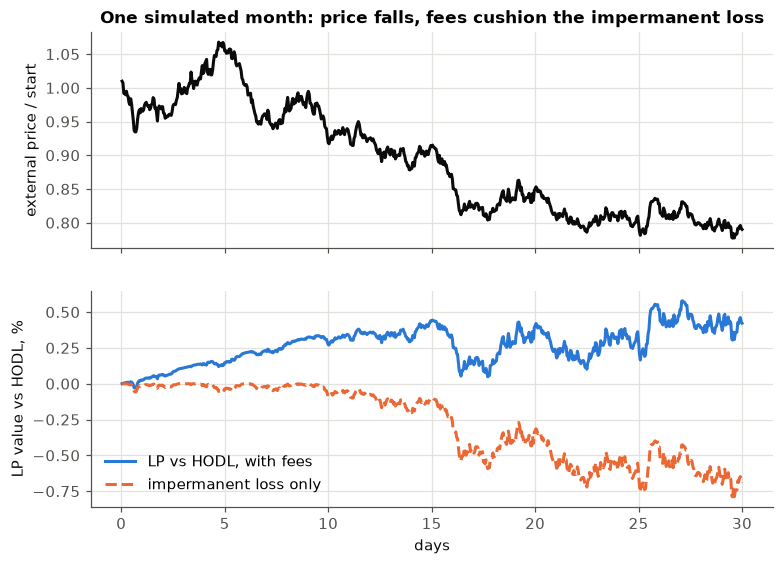

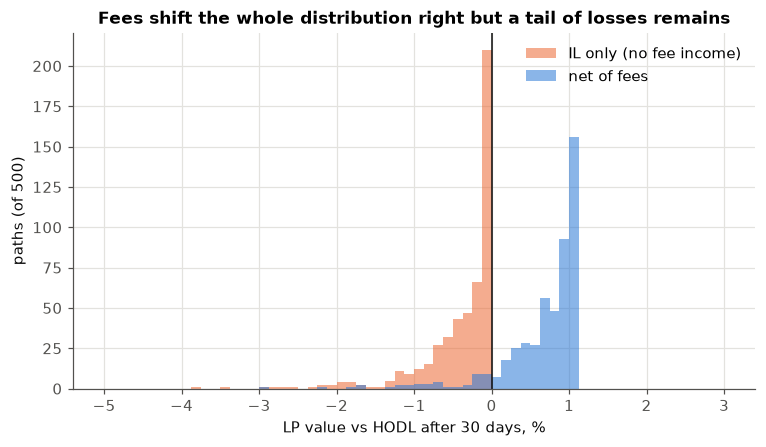

In [9]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
hours = np.arange(1, base["P"].shape[0] + 1) / 24
i = int(np.argsort(base["P"][-1])[len(base["P"][-1]) // 10])   # a path that ends well below the start (10th percentile)
a1.plot(hours, base["P"][:, i] / P0, color=INK); a1.set_ylabel("external price / start")
a1.set_title("One simulated month: price falls, fees cushion the impermanent loss")
a2.plot(hours, base["ratio"][:, i] * 100, color=BLUE, label="LP vs HODL, with fees")
a2.plot(hours, il_closed(base["P"][:, i] / P0) * 100, color=ORANGE, ls="--", label="impermanent loss only")
a2.set_xlabel("days"); a2.set_ylabel("LP value vs HODL, %"); a2.legend(); plt.show()

fig, ax = plt.subplots()
bins = np.linspace(-5, 3, 65)
ax.hist(base["il"] * 100, bins=bins, color=ORANGE, alpha=0.55, label="IL only (no fee income)")
ax.hist(base["net"] * 100, bins=bins, color=BLUE, alpha=0.55, label="net of fees")
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel("LP value vs HODL after 30 days, %"); ax.set_ylabel("paths (of 500)")
ax.set_title("Fees shift the whole distribution right but a tail of losses remains"); ax.legend(); plt.show()

**Reading it.** In the base case organic volume earns about 0.03 percentage points of TVL a day (6M a day at 30 bps on 60M TVL), roughly 0.9 over the month, and arbitrage trades add a little more. Mean fees are 1.07 points against mean IL of -0.38, so the LP ends 0.68% ahead of HODL on average and beats it on 92% of paths. The paths where it loses are the big one-way moves, where IL exceeds a month of fees.

## 4. Sensitivity to fee, depth and volatility

Volume is held at a fixed 6M USD a day in the fee and volatility sweeps. In the depth sweep it is also fixed in dollars, so a deeper pool earns the same dollars of fees on more capital.

Mean net LP vs HODL after 30 days, %


,vol 30%,vol 60%,vol 100%
5 bps,0.073,-0.191,-0.838
30 bps,0.862,0.683,0.172
100 bps,2.984,2.894,2.590


Share of paths where the LP beats HODL, %


,vol 30%,vol 60%,vol 100%
5 bps,81.4,51.0,33.8
30 bps,99.8,91.6,69.6
100 bps,100.0,99.8,94.8


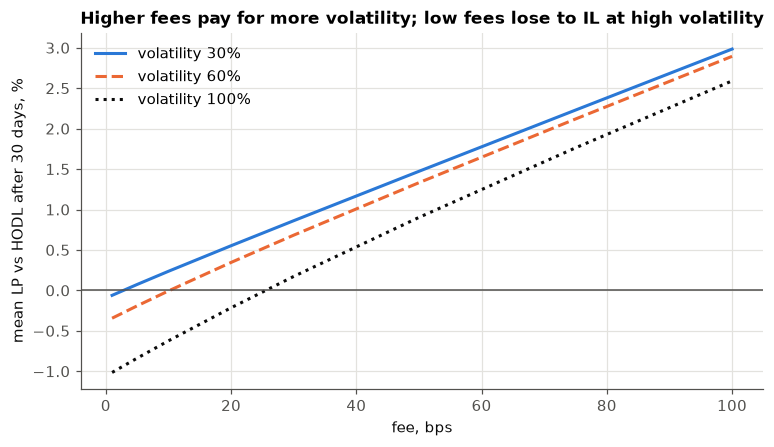

In [10]:
fees_bps = [5, 30, 100]
vols = [0.30, 0.60, 1.00]
grid = {(f, v): summary(simulate(fee_bps=f, vol=v)) for f in fees_bps for v in vols}
mean_net = pd.DataFrame({f"vol {int(v*100)}%": [grid[(f, v)]["mean net %"] for f in fees_bps] for v in vols},
                        index=[f"{f} bps" for f in fees_bps]).round(3)
p_win = pd.DataFrame({f"vol {int(v*100)}%": [grid[(f, v)]["P(net > 0) %"] for f in fees_bps] for v in vols},
                     index=[f"{f} bps" for f in fees_bps]).round(1)
print("Mean net LP vs HODL after 30 days, %"); display(mean_net)
print("Share of paths where the LP beats HODL, %"); display(p_win)

fee_axis = np.array([1, 5, 10, 20, 30, 50, 75, 100])
fig, ax = plt.subplots()
for v, col, ls in [(0.30, BLUE, "-"), (0.60, ORANGE, "--"), (1.00, INK, ":")]:
    ax.plot(fee_axis, [summary(simulate(fee_bps=f, vol=v))["mean net %"] for f in fee_axis], color=col, ls=ls, label=f"volatility {int(v*100)}%")
ax.axhline(0, color=MUTED, lw=1); ax.set_xlabel("fee, bps"); ax.set_ylabel("mean LP vs HODL after 30 days, %")
ax.set_title("Higher fees pay for more volatility; low fees lose to IL at high volatility"); ax.legend(); plt.show()

In [11]:
depth_btc = [100, 500, 2000, 10000]
rows = []
for d in depth_btc:
    res = simulate(x0=float(d))
    s = summary(res); s["depth (BTC)"] = d; s["TVL (M USD)"] = 2 * d * P0 / 1e6
    s["daily volume / TVL %"] = 6e6 / (2 * d * P0) * 100
    rows.append(s)
depth_tbl = pd.DataFrame(rows).set_index("depth (BTC)")[["TVL (M USD)", "daily volume / TVL %", "mean IL %", "mean fees %", "mean net %", "P(net > 0) %"]].round(3)
display(depth_tbl)

# Break-even volume: mean net is close to linear in organic volume, so interpolate from two runs.
be = []
for v in vols:
    lo, hi = summary(simulate(vol=v, volume_usd_day=0))["mean net %"], summary(simulate(vol=v, volume_usd_day=6e6))["mean net %"]
    per_usd = (hi - lo) / 6e6
    vol_be = max(0.0, -lo / per_usd)
    be.append({"volatility": f"{int(v*100)}%", "mean net with no organic volume %": lo, "break-even organic volume (USD/day)": vol_be,
               "as % of 60M TVL per day": vol_be / 60e6 * 100})
pd.DataFrame(be).round(3)

,TVL (M USD),daily volume / TVL %,mean IL %,mean fees %,mean net %,P(net > 0) %
depth (BTC),,,,,,
100,12.0,50.0,-0.383,4.674,4.291,100.0
500,60.0,10.0,-0.383,1.066,0.683,91.6
2000,240.0,2.5,-0.383,0.389,0.006,66.4
10000,1200.0,0.5,-0.383,0.209,-0.174,52.2


,volatility,mean net with no organic volume %,break-even organic volume (USD/day),as % of 60M TVL per day
0,30%,-0.039,260218.290,0.434
1,60%,-0.219,1458496.343,2.431
2,100%,-0.733,4857073.148,8.095


## 5. What to take away, and what the model leaves out

- **Price impact** is driven by trade size as a fraction of reserves. A 50 BTC trade costs 9.3% in a 500 BTC pool but about 1.3% in a 5,000 BTC pool, so depth is what makes a large order cheap, and what slicing is trying to buy time to recover (Part B).
- **Impermanent loss** is a pure function of the price move: 5.7% at 2x or 0.5x, 20% at 4x. The 30 bps fee on a single arbitrage trade barely changes it outside a narrow band around the start.
- **LP economics** depend on volume per dollar of liquidity. At fixed dollar volume a deeper pool earns less per dollar, so the fee yield falls as depth rises while IL does not. The break-even table says how much organic volume covers the expected IL: about 0.4%, 2.4% and 8.1% of the 60M TVL per day at 30%, 60% and 100% volatility. In the depth sweep, a pool 20x deeper than the base case (10,000 BTC) earns only 0.2 points of fees in the month and ends slightly behind HODL on average.
- **Not modelled:** gas costs and the competition that stops arbitrage being instant and free (A5), correlation between volume and volatility (A6; in reality volume spikes when price moves), a protocol fee cut (A8), and fees earned by arbitrageurs being partly taken by MEV searchers. All of these would make real LP returns lower than the numbers here, not higher.
- **Reconciliation hook:** the `Hand-computed vector` cell in section 0 produces one exact swap output; the Hardhat test `Pool.swapExactIn` will assert the same number.